<a href="https://colab.research.google.com/github/MarwaSal/risk-impact-modelling/blob/main/blast-radius-risk-model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**The problem**:

In October 2026, two critical vulnerabilities were disclosed in PHP — a language running on roughly three-quarters of the world’s web servers, affecting virtually every version released over the last decade. The flaws allowed unauthenticated remote control of the server. The NCSC called it an extremely serious risk.

The response was immediate: more than thirty UK government services were taken offline.

> But taking everything down at once causes service interruption at scale, and that has consequences of its own — not unlike compromising all of them at once, but if we don’t do that, then how do we know what to deal with first?

A severity score cannot answer that. Every instance of the same vulnerability carries the same score. It tells you how severe the flaw is, and nothing about its cascading effect — the realistic impact of the thing it exposes.

**The answer has to come from the structure.** And the solution has to answer these questions:

1. What services does the product provide, and how critical is each one’s data?
2. Which of them are exposed to the internet?
3. If one service goes down, what goes down with it?
4. Accordingly, how do we prioritise what to patch or take offline first
5. And what fails immediately, rather than eventually?

Those questions tell us what data we need.

**The data:**

| Component | What we need |
|---|---|
| **Service** | `service_id`, `service_name`, `internet_facing` (true/false), `data_tier` (public / internal / confidential / highly confidential), `data_tier_weight` (1–4) |
| **Dependency** | `service_id`, `depends_on_service_id` |

That answers the first three questions. To answer all the questions, we need to build a model.

**The model:**

A directed graph.
- **Nodes** are services, each carrying its exposure and data tier
- **Edges** are dependencies — an edge from A to B means **A depends on B**

The diagram in the following cell shows a product providing services, services depending on one another, and data stores that several services share. To answer the above five questions only the services and their dependencies are needed, so that is what the analysis uses, also the model is infrusturcture agnostic.


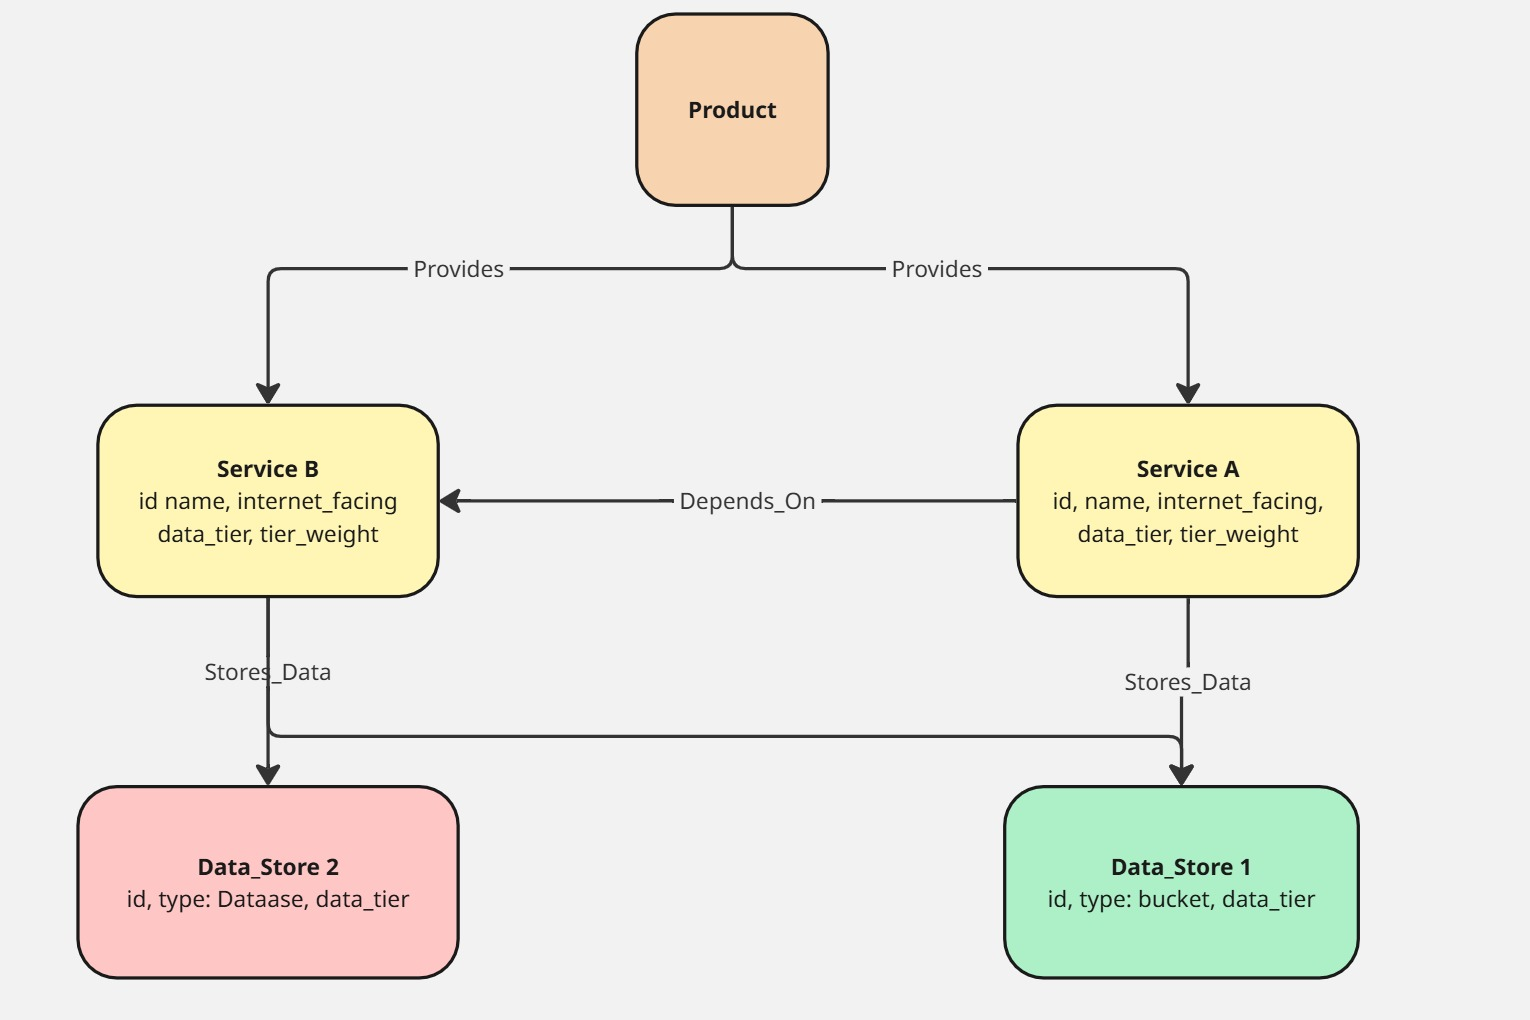

In [ ]:
from IPython.display import Image, display
display(Image("Model.jpg", width=500))

#display(Image("Example.jpg", width=500))

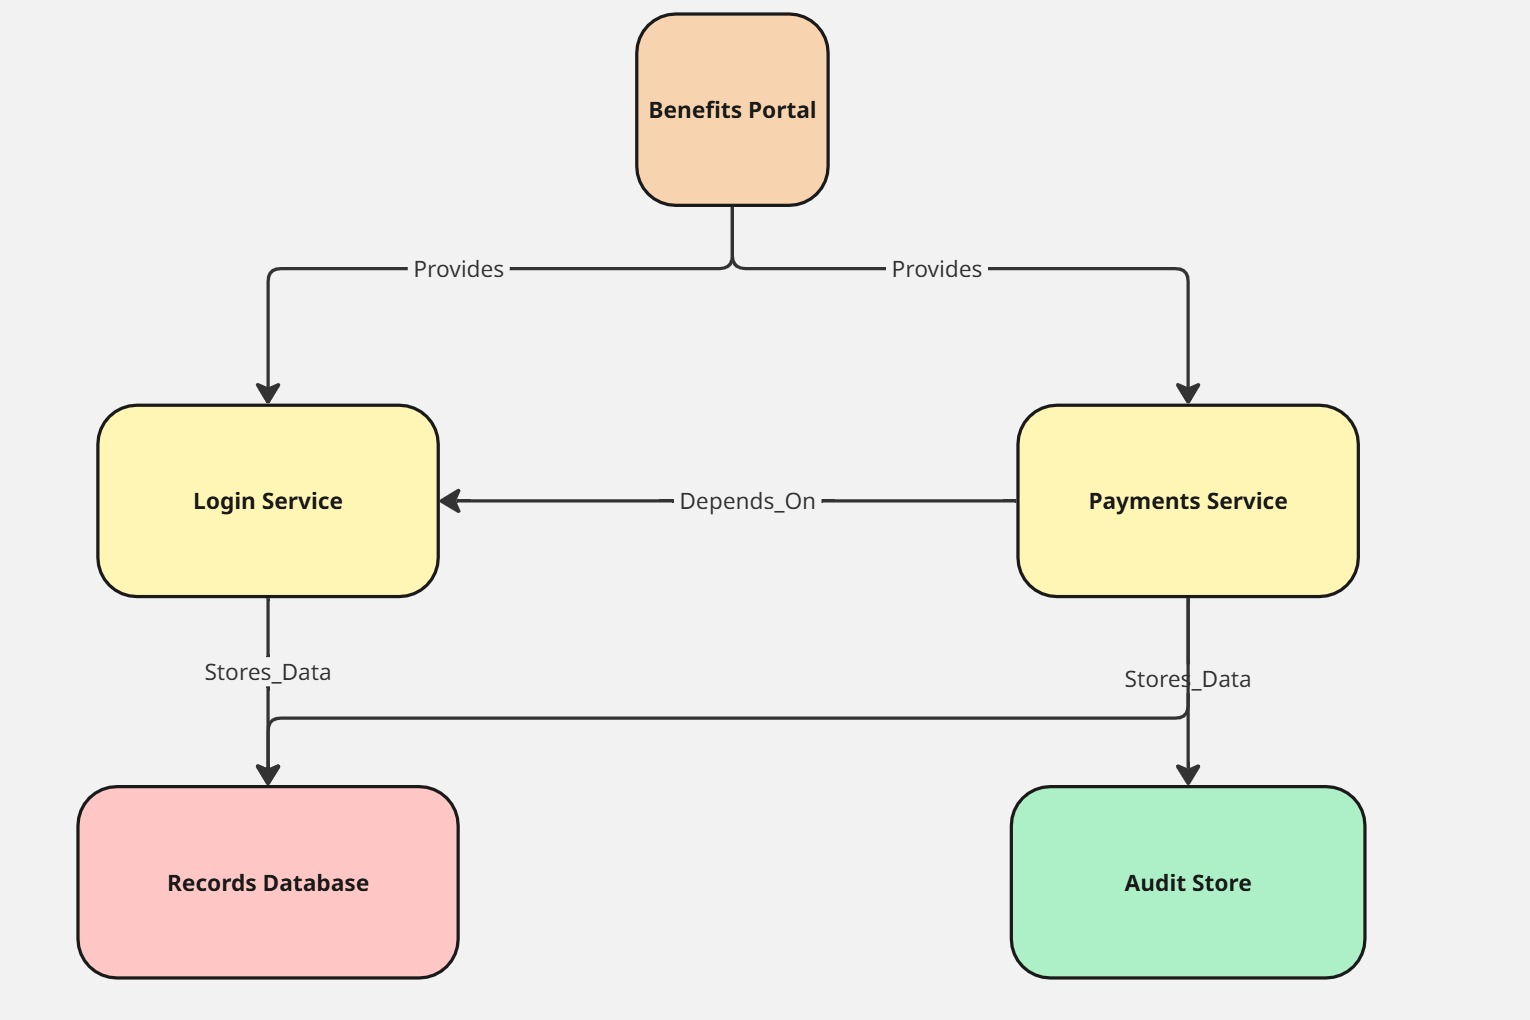

In [ ]:
display(Image("Example.jpg", width=500))

In [ ]:
# ===============================================================
# Functions used by every cell below:
# Risk bands and the scaling rule
# ===============================================================
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


def to_score(column):
    """Scale a measure to 0-100 so the versions can be compared.

    Divide every value by the largest one, then multiply by 100:
    the highest becomes 100 and everything else sits below it.
    This is min-max normalisation, with the minimum at zero.
    """
    return (column / column.max() * 100).round(1)


def risk_level(score):
    """Turn a 0-100 score into a reporting band."""
    if score >= 65:
        return "HIGH"
    elif score >= 35:
        return "MEDIUM"
    else:
        return "LOW"


def add_levels(score_column):
    """Apply risk_level to a whole column of scores."""
    levels = []
    for score in score_column:
        levels.append(risk_level(score))
    return levels


def rank_by(score_column, extra_columns):
    """Sort by a score and print the top ten.

    score_column  : the column to rank on, e.g. "v2"
    extra_columns : a list of other columns to show alongside it
    """
    ranked = services.sort_values(score_column, ascending=False)
    columns = ["service_name"] + extra_columns + [score_column]
    print(ranked[columns].head(10)) #.to_string(index=False))
    print()


def count_levels(level_column):
    """How many services fall in each band."""
    print(services[level_column].value_counts().to_string())
    print()


In [ ]:
# ===============================================================
# How do we prioritise what to patch or take offline first
# The conventional approach:
# ===============================================================

services = pd.read_csv("services.csv")
dependencies = pd.read_csv("dependencies.csv")

print(services.head())
print(dependencies.head())

# --- risk v1 -------------------------------------------------------
# risk = exposure x impact.
# At this stage "impact" is only the service's own data tier (traditional approach)


# --- exposure -----------------------------------------------------
# Internet-facing services are fully reachable. Internal services are
# not risk-free — an attacker already inside can reach them — so they
# carry a reduced factor rather than zero. 0.3 is an assumption

exposure_factor = []
for exposed in services["internet_facing"]:
    if exposed:
        exposure_factor.append(1.0)
    else:
        exposure_factor.append(0.3)
services["exposure_factor"] = exposure_factor     # attach as a new column



services["v1"] = to_score(services["exposure_factor"] * services["data_tier_weight"])


services["level_v1"] = add_levels(services["v1"])


rank_by("v1", ["internet_facing", "data_tier", "level_v1"])
print()
count_levels("level_v1")


  service_id      service_name  internet_facing     data_tier  \
0     SVC001       api-gateway             True        public   
1     SVC002      web-frontend             True        public   
2     SVC003  identity-service             True  confidential   
3     SVC004  customer-profile            False  confidential   
4     SVC005   catalog-service             True      internal   

   data_tier_weight  
0                 1  
1                 1  
2                 3  
3                 3  
4                 2  
  service_id depends_on_service_id
0     SVC001                SVC003
1     SVC001                SVC039
2     SVC002                SVC001
3     SVC002                SVC005
4     SVC003                SVC025
            service_name  internet_facing            data_tier level_v1     v1
2       identity-service             True         confidential     HIGH  100.0
32    support-portal-api             True         confidential     HIGH  100.0
33   partner-integration      

40 services
68 dependencies
SVC007 depends on: ['SVC003', 'SVC008', 'SVC010']
services depend on SVC003: ['SVC001', 'SVC004', 'SVC007', 'SVC017', 'SVC023', 'SVC033', 'SVC034', 'SVC038']
in-degree of SVC003: 8


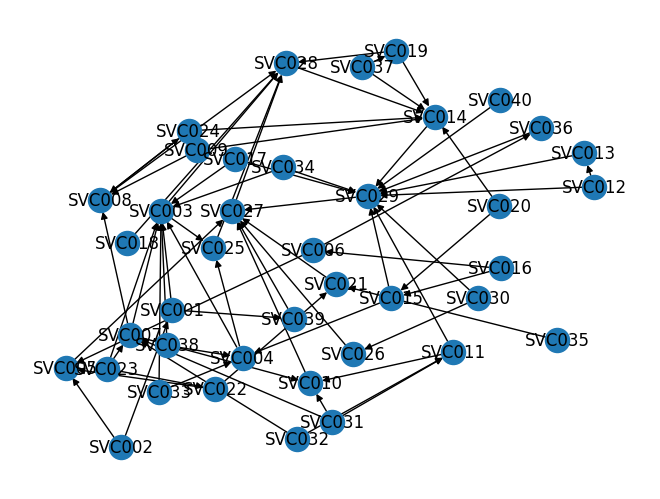

In [ ]:
# ===============================================================
# The dependency structure everything else is computed from.
# ===============================================================

# DiGraph = directed graph. An edge A --> B means "A depends on B".
G = nx.DiGraph()

# iterrows() walks the table one row at a time, returning (index, row).
# We do not need the index, so we call it "_" — Python's "ignore this".
for _, row in services.iterrows():
    G.add_node(row["service_id"],
               name=row["service_name"],
               tier_weight=row["data_tier_weight"])

for _, row in dependencies.iterrows():
    G.add_edge(row["service_id"], row["depends_on_service_id"])

print(G.number_of_nodes(), "services")
print(G.number_of_edges(), "dependencies")


# --- the two directions --------------------------------------------
# successors   : follow arrows FORWARD  — what this service depends on
# predecessors : follow arrows BACKWARD — what depends on this service
# in_degree    : how MANY depend on it directly

print("SVC007 depends on:", list(G.successors("SVC007")))
print("services depend on SVC003:", list(G.predecessors("SVC003")))
print("in-degree of SVC003:", G.in_degree("SVC003"))

# the deafault drawing
nx.draw(G, with_labels=True)
plt.show()


In [ ]:

# LAYOUT OPTIONS:
#   nx.kamada_kawai_layout(G)      evenly spread — best for this graph
#   nx.spring_layout(G, seed=42)   nodes repel each other; the default
#   nx.circular_layout(G)          all nodes on a circle
#   nx.shell_layout(G)             concentric circles
layout = nx.kamada_kawai_layout(G)

# zip() pairs two columns; dict() turns the pairs into a lookup
names = dict(zip(services["service_id"], services["service_name"]))


def show_graph(score_column, title):
    """Draw the estate, coloured and sized by any score column."""
    scores = dict(zip(services["service_id"], services[score_column]))
    colours = []
    for service_id in G.nodes:
        level = risk_level(scores[service_id])
        if level == "HIGH":
            colours.append("red")
        elif level == "MEDIUM":
            colours.append("orange")
        else:
            colours.append("green")



    # 100 is a minimum size, so low-scoring nodes stay visible
    sizes = [100 + scores[service_id] * 8 for service_id in G.nodes]

    plt.figure(figsize=(12, 8))          # width, height in inches
    nx.draw(G, layout,
            labels=names,
            node_color=colours,
            node_size=sizes,
            font_size=7,
            edge_color="lightgrey",
            arrows=True)
    plt.title(title)
    plt.show()


         service_name  in_degree
            event-bus         10
     identity-service          8
        audit-service          6
configuration-service          6
        secrets-vault          6
     customer-profile          3


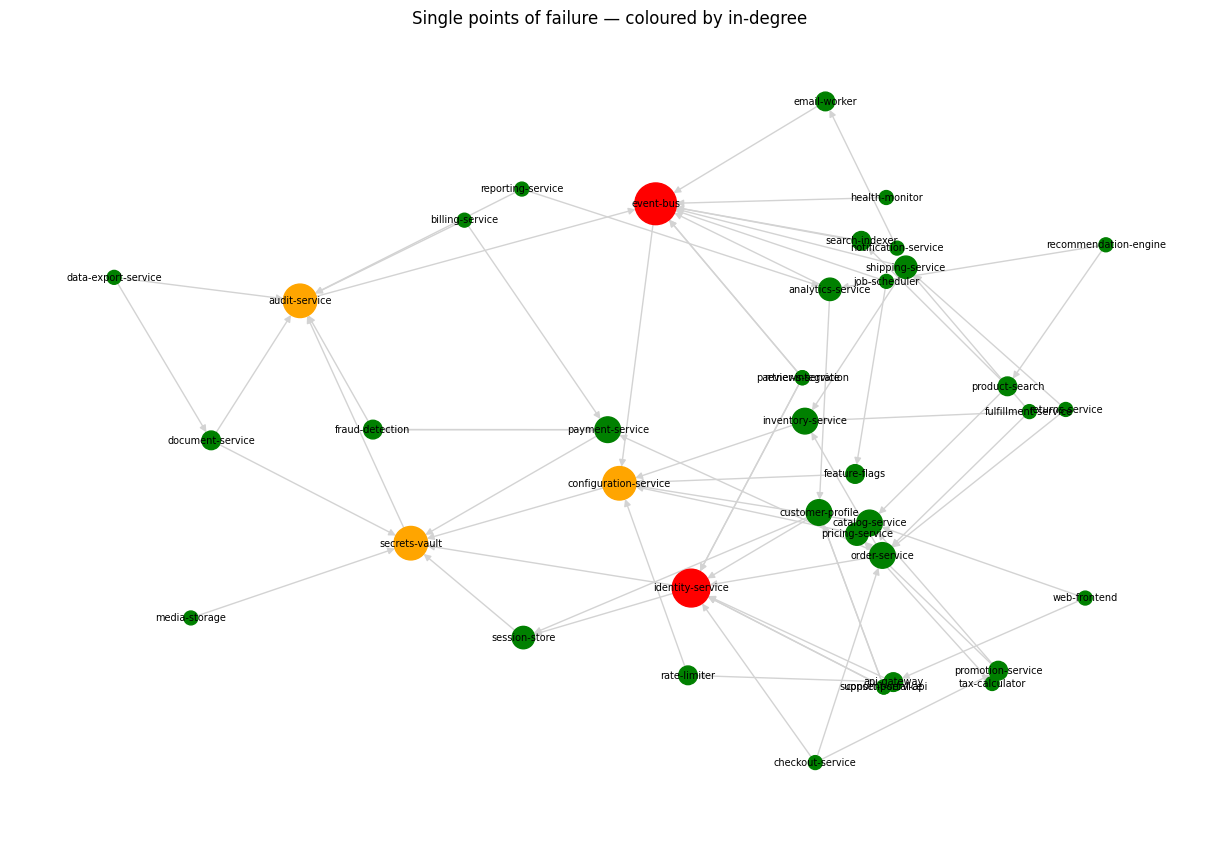

In [ ]:
# ===============================================================
# How many services depend on each one DIRECTLY?
#
# in-degree counts dependents without asking what they hold.
# ===============================================================

in_degrees = []
for service_id in services["service_id"]:
    in_degrees.append(G.in_degree(service_id))
services["in_degree"] = in_degrees

# scale to 0-100, because show_graph colours at thresholds of 65 and 35
services["in_degree_score"] = to_score(services["in_degree"])

# nlargest(6, "col")      = the six rows with the biggest value there
# [["a", "b"]]            = keep only those two columns
# .to_string(index=False) = print as plain text, without row numbers
print(services.nlargest(6, "in_degree")[["service_name", "in_degree"]].to_string(index=False))

show_graph("in_degree_score", "Single points of failure — coloured by in-degree")


             service_name  internet_facing            data_tier  blast_radius  \
2        identity-service             True         confidential            14   
13          audit-service            False  highly confidential            39   
27          secrets-vault            False  highly confidential            39   
26  configuration-service            False             internal            39   
28              event-bus            False             internal            39   
4         catalog-service             True             internal             5   
24          session-store            False         confidential            15   
5          product-search             True             internal             1   
32     support-portal-api             True         confidential             0   
33    partner-integration             True         confidential             0   

   level_v2     v2  
2      HIGH  100.0  
13     HIGH   75.9  
27     HIGH   75.9  
26     HIGH   72.4  
28 

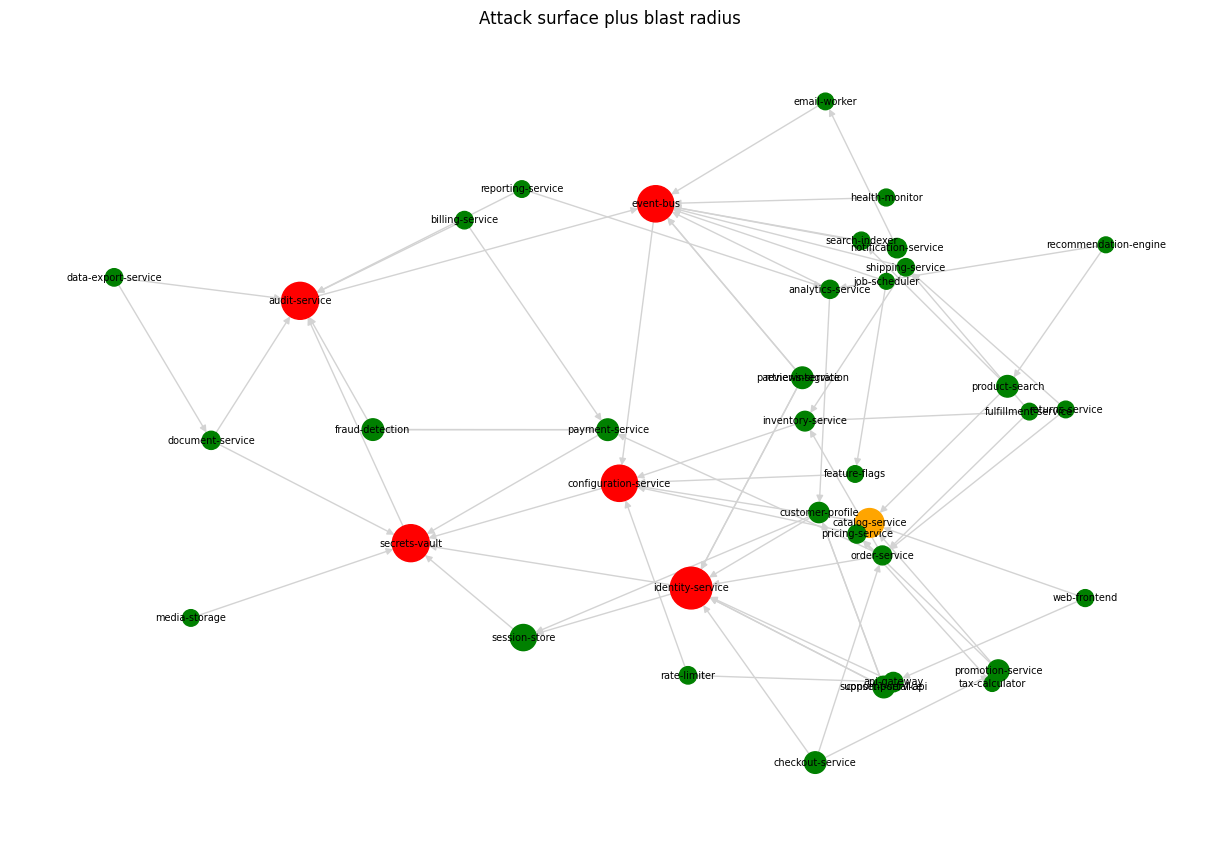

In [ ]:
# ===============================================================
# The cascading effect.
# The risk formula does not change: exposure x impact.
# What changes is that impact now includes the services downstream,
# not just the service's own data.
# ===============================================================

def blast_radius_count(service_id):
    """Every service that depends on this one, directly or indirectly.

    nx.ancestors follows the dependency edges backwards through the
    whole graph, so it returns the entire chain, not just the first hop.
    """
    return len(nx.ancestors(G, service_id))

services["blast_radius"] = services["service_id"].apply(blast_radius_count)



# impact is now: the service's own data tier PLUS how many depend on it.


services["v2"] = to_score(services["exposure_factor"] *
                         (services["data_tier_weight"] + services["blast_radius"]))

services["level_v2"] = add_levels(services["v2"])

rank_by("v2", ["internet_facing", "data_tier", "blast_radius", "level_v2"])
count_levels("level_v2")

show_graph("v2", "Attack surface plus blast radius")


             service_name  blast_radius  impact level_v3     v3
2        identity-service            14      35     HIGH  100.0
26  configuration-service            39     101     HIGH   81.3
28              event-bus            39     101     HIGH   81.3
13          audit-service            39      99     HIGH   81.3
27          secrets-vault            39      99     HIGH   81.3
24          session-store            15      38      LOW   32.4
4         catalog-service             5      10      LOW   31.6
7         payment-service             6      20      LOW   18.9
23        fraud-detection             6      20      LOW   18.9
3        customer-profile             5      14      LOW   13.4

level_v3
LOW     35
HIGH     5



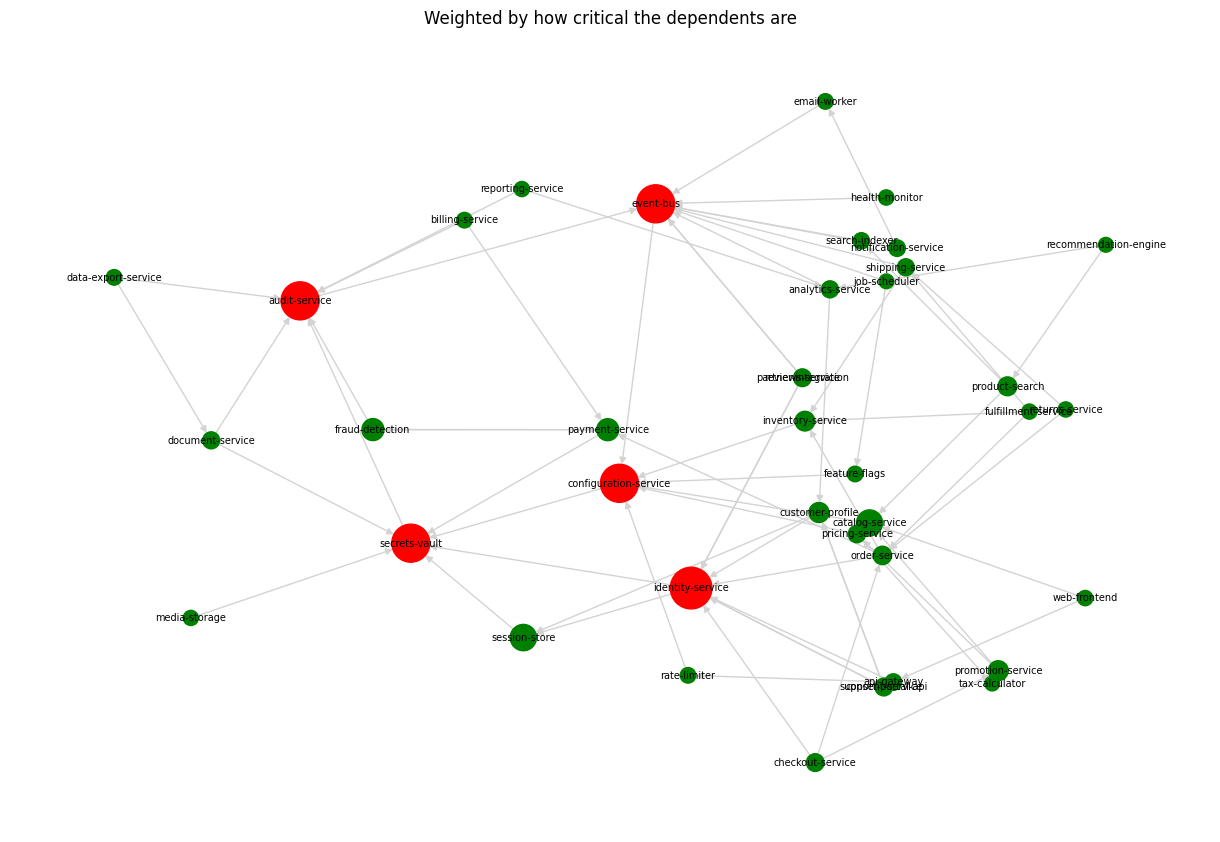

In [ ]:
# ===============================================================
# Counting dependents treats them all as equal. Ten dependents
# holding public data are not the same as one holding the most
# sensitive data in the system.
#
# So instead of only counting them, we add up how critical they are.
# ===============================================================

def weighted_impact(service_id):
    """Total data tier of every service that depends on this one."""
    total = 0
    for dependent in nx.ancestors(G, service_id):
        total = total + G.nodes[dependent]["tier_weight"]
    return total

services["impact"] = services["service_id"].apply(weighted_impact)


services["v3"] = to_score(services["exposure_factor"] *
                         (services["data_tier_weight"] + services["impact"]))


services["level_v3"] = add_levels(services["v3"])

rank_by("v3", ["blast_radius", "impact", "level_v3"])

count_levels("level_v3")

show_graph("v3", "Weighted by how critical the dependents are")


             service_name  in_degree  direct_impact  direct_score
13          audit-service          6             23         100.0
28              event-bus         10             22          95.7
2        identity-service          8             20          87.0
27          secrets-vault          6             19          82.6
26  configuration-service          6             12          52.2
7         payment-service          3             11          47.8
6           order-service          3              9          39.1
3        customer-profile          3              9          39.1
9       inventory-service          3              8          34.8
24          session-store          2              6          26.1



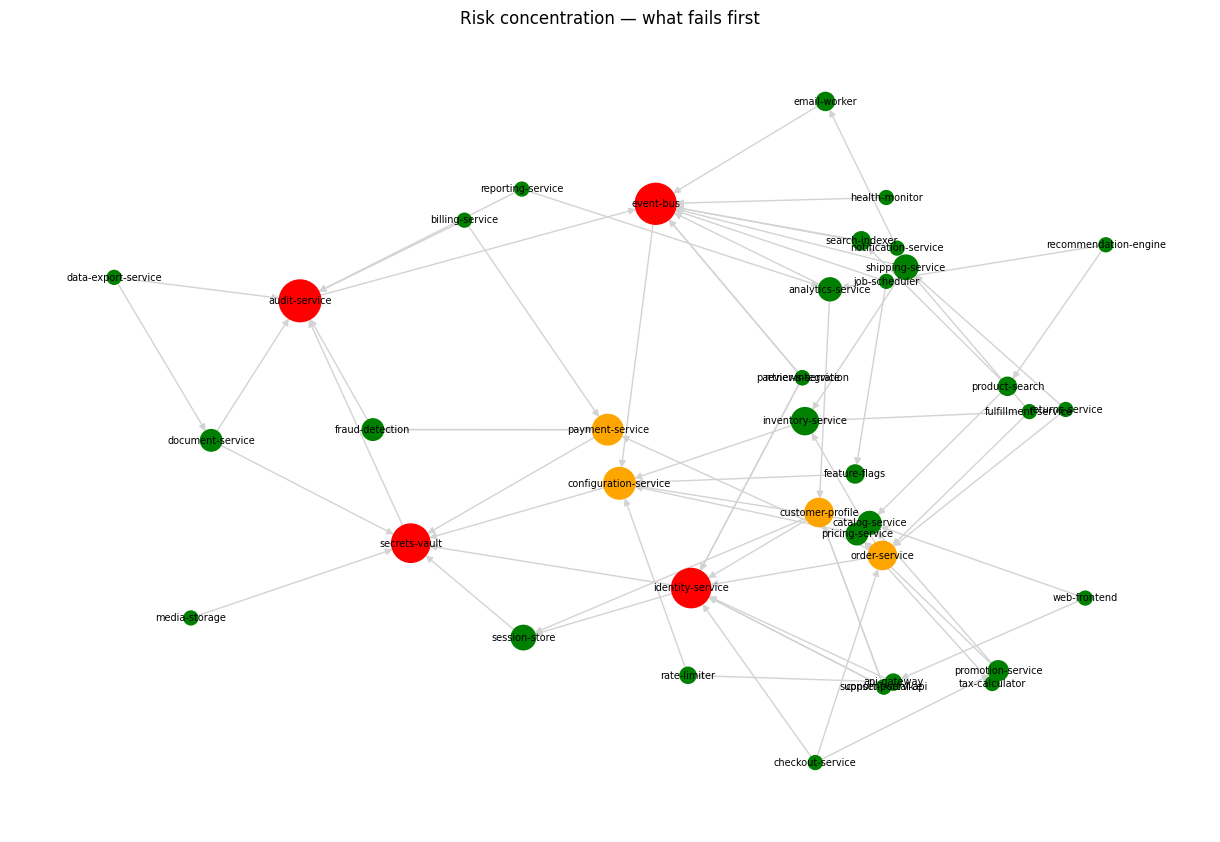

In [ ]:
def direct_impact(service_id):
    """Total data tier of the services depending on this one DIRECTLY."""
    total = 0
    for dependent in G.predecessors(service_id):      # one hop only
        total = total + G.nodes[dependent]["tier_weight"]
    return total

services["direct_impact"] = services["service_id"].apply(direct_impact)

services["direct_score"] = to_score(services["direct_impact"])

rank_by("direct_score", ["in_degree", "direct_impact"])

show_graph("direct_score", "Risk concentration — what fails first")


         service_name  data_tier_weight  impact  rank_v1  rank_v3  moved
configuration-service                 2     101     29.0      2.0   27.0
            event-bus                 2     101     29.0      2.0   27.0
    inventory-service                 2      14     29.0     12.0   17.0
        session-store                 3      38     20.0      6.0   14.0
      pricing-service                 2       7     29.0     18.0   11.0
     customer-profile                 3      14     20.0     10.0   10.0


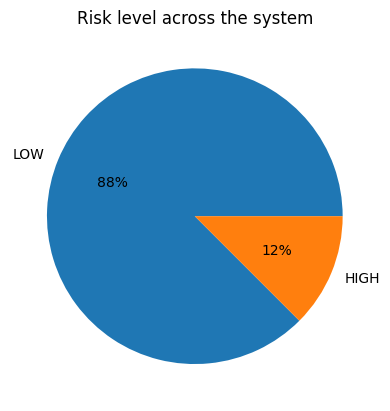

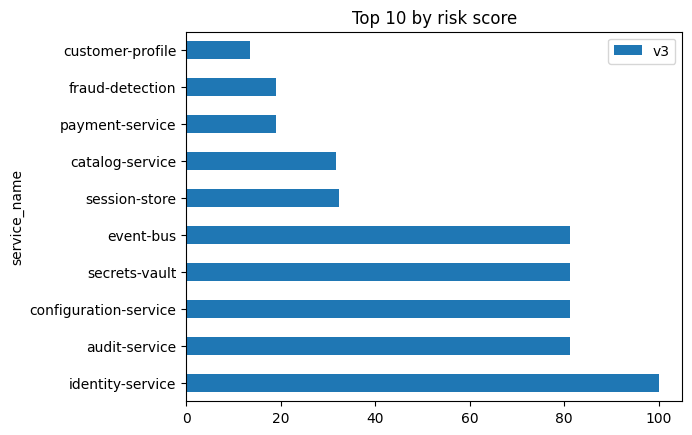

In [ ]:
from networkx.algorithms.matching import min_weight_matching
# ===============================================================
# Did the ranking actually change?
#
# Version 1 ranks by attack surface. Version 3 includes the
# structure.
# ===============================================================

# rank() turns scores into positions — 1st, 2nd, 3rd.
#sort_values reorders the rows but rank leaves the rows where they are and adds a column saying what position each would be in
services["rank_v1"] = services["v1"].rank(ascending=False, method="min") # services with same score share the lowest position,
services["rank_v3"] = services["v3"].rank(ascending=False, method="min")

# how far each service moved between the two
services["moved"] = services["rank_v1"] - services["rank_v3"]

print(services.nlargest(6, "moved")[["service_name", "data_tier_weight",
      "impact", "rank_v1", "rank_v3", "moved"]].to_string(index=False))


# ===============================================================
# Charts
# ===============================================================

services["level_v3"].value_counts().plot.pie(autopct="%1.0f%%")
plt.title("Risk level across the system")
plt.ylabel("")
plt.show()


services.nlargest(10, "v3").plot.barh(x="service_name", y="v3")
plt.title("Top 10 by risk score")
plt.show()



In [ ]:
# ===============================================================
# Checking the answer independently
#
# The analysis above uses a graph library. This recomputes the same
# answer by filtering the dependency table directly.
# Automated across all forty services.
# ===============================================================

def depends_on_me(service_id, found=None):
    """Every service that depends on this one, directly or indirectly.

    Filters the dependency table for rows pointing at this service,
    then calls itself on each one it finds. The `found` list stops it
    going round in circles where services depend on each other.
    """
    if found is None:          # first call — start a fresh list
        found = []

    # filter the table for rows where this service is depended on
    rows = dependencies[dependencies["depends_on_service_id"] == service_id]

    for dependent in rows["service_id"]:
        if dependent not in found:
            found.append(dependent)
            depends_on_me(dependent, found)

    return found


# --- compare against the graph ---
check = []

for service_id in services["service_id"]:

    mine = depends_on_me(service_id)

    # a cycle can bring us back to the service we started from
    if service_id in mine:
        mine.remove(service_id)

    row = services[services["service_id"] == service_id]

    check.append({"service":     service_id,
                  "my_blast":    len(mine),
                  "graph_blast": int(row["blast_radius"].values[0])})

check_df = pd.DataFrame(check)

print(check_df.sort_values("my_blast", ascending=False).head(8).to_string(index=False))
print()


service  my_blast  graph_blast
 SVC028        39           39
 SVC027        39           39
 SVC029        39           39
 SVC014        39           39
 SVC025        15           15
 SVC003        14           14
 SVC024         6            6
 SVC008         6            6



In [ ]:
#Evaluating the perfrmance

import time

start = time.time()
for service_id in services["service_id"]:
    depends_on_me(service_id)
print("recursive check:", round(time.time() - start, 4), "seconds")

start = time.time()
for service_id in services["service_id"]:
    nx.ancestors(G, service_id)
print("graph traversal:", round(time.time() - start, 5), "seconds")

recursive check: 0.0591 seconds
graph traversal: 0.00045 seconds
